In [231]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OrdinalEncoder

from sklearn.linear_model import LinearRegression,Lasso, Ridge
from sklearn.metrics import mean_squared_error, r2_score

%matplotlib inline
sns.set_theme(style = "whitegrid")
print("All libraries loaded successfully!")

All libraries loaded successfully!


# Task 01

In [232]:
# dataset loading
df = pd.read_csv("diamonds.csv")

# shape printing
print(f"Shape : {df.shape}")

# column type printing
print(f"Columns Data Types : {df.dtypes}")

# first 5 rows printing
print(df.head(5))

Shape : (53940, 10)
Columns Data Types : carat      float64
cut         object
color       object
clarity     object
depth      float64
table      float64
x          float64
y          float64
z          float64
price        int64
dtype: object
   carat      cut color clarity  depth  table     x     y     z  price
0   0.23    Ideal     E     SI2   61.5   55.0  3.95  3.98  2.43    326
1   0.21  Premium     E     SI1   59.8   61.0  3.89  3.84  2.31    326
2   0.23     Good     E     VS1   56.9   65.0  4.05  4.07  2.31    327
3   0.29  Premium     I     VS2   62.4   58.0  4.20  4.23  2.63    334
4   0.31     Good     J     SI2   63.3   58.0  4.34  4.35  2.75    335


In [233]:
# count rows with zero physical dimension
bad = df[(df['x'] == 0) | (df['y'] == 0) | (df['z'] == 0)]
print(f"\nRows with x=0, y=0, or z=0 (invalid): {len(bad)}")

# removing invalid rows
df_clean = df[(df['x'] > 0) & (df['y'] > 0) & (df['z'] > 0)].copy()
print(f"Rows before remove: {len(df)}")
print(f"Rows after remove: {len(df_clean)}")


Rows with x=0, y=0, or z=0 (invalid): 20
Rows before remove: 53940
Rows after remove: 53920


In [234]:
# random sampling
df_sample = df_clean.sample(n=5000, random_state=42).reset_index(drop=True)

print(f"Sample shape: {df_sample.shape}")

Sample shape: (5000, 10)


In [235]:
# ordinal encoding
cut_order = ['Fair', 'Good', 'Very Good', 'Premium', 'Ideal']
color_order = ['J', 'I', 'H', 'G', 'F', 'E', 'D']
clarity_order = ['I1', 'SI2', 'SI1', 'VS2', 'VS1', 'VVS2', 'VVS1', 'IF']

enc = OrdinalEncoder(categories=[cut_order,color_order,clarity_order])

df_sample[['cut','color','clarity']] = enc.fit_transform(
  df_sample[['cut','color','clarity']]
)

In [236]:
# feature selection
feature_cols = ['carat', 'cut', 'color', 'clarity', 'depth', 'table', 'x', 'y', 'z']
target_col = 'price'

X_raw = df_sample[feature_cols].values.astype(float)
y = df_sample[target_col].values.astype(float)

print("Feature matrix shape:", X_raw.shape)
print("Target vector shape:", y.shape)

Feature matrix shape: (5000, 9)
Target vector shape: (5000,)


In [237]:
# 80% training 20% test splitting
X_train, X_test, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.2, random_state=42
)

print(f"Training samples:{X_train.shape[0]}")
print(f"Test samples: {X_test.shape[0]}")
print(f"Number of features: {X_train.shape[1]}")

Training samples:4000
Test samples: 1000
Number of features: 9


In [238]:
# feature scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nTraining feature means (should be ~0):")
print(X_train_scaled.mean(axis=0).round(4))

print("\nTraining feature stds (should be ~1):")
print(X_train_scaled.std(axis=0).round(4))


Training feature means (should be ~0):
[-0. -0.  0. -0. -0. -0.  0. -0.  0.]

Training feature stds (should be ~1):
[1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [239]:
# adding bias
def add_bias(X):
    ones = np.ones((X.shape[0], 1))
    return np.hstack([ones, X])

X_train_b = add_bias(X_train_scaled)
X_test_b = add_bias(X_test_scaled)

print("\nShape after adding bias column:")
print("X_train_b shape:", X_train_b.shape)
print("X_test_b shape:", X_test_b.shape)


Shape after adding bias column:
X_train_b shape: (4000, 10)
X_test_b shape: (1000, 10)


# Task 02

In [240]:
# hypothesis functions
def predict_single(x, w):
  prediction = 0.0

  for i in range(len(x)):
    prediction += x[i] * w[i]

  return prediction

In [241]:
def predict(X, w):
  predictions = []

  for i in range(len(X)):
    predictions.append(predict_single(X[i], w))

  return np.array(predictions)

In [242]:
w_initial = np.zeros(X_train_b.shape[1])

initial_prediction = predict(X_train_b, w_initial)

print("First 5 predicted values: ", initial_prediction[:5])
print("First 5 actual values: ", y_train[:5])

First 5 predicted values:  [0. 0. 0. 0. 0.]
First 5 actual values:  [ 2033. 16709.  1819.   791.  3018.]


In [243]:
# mse loss
def mse_loss(X, y, w):
  size = len(X)
  total_squared_error = 0.0

  for i in range(size):
    y_pred = predict_single(X[i], w)

    error = y_pred - y[i]

    total_squared_error += (error * error)
  return (total_squared_error / size)

In [244]:
w_init = np.zeros(X_train_b.shape[1])

initial_mse = mse_loss(X_train_b, y_train, w_init)

print("Initial MSE:", initial_mse)

Initial MSE: 30262865.9335


# Task 03

In [245]:
def compute_gradients(X, y, w):
  n = X.shape[0]
  d = len(w)
  gradients = np.zeros(d)

  predictions = predict(X, w)

  for j in range(d):
    gradient_sum = 0.0
    for i in range(n):
      gradient_sum += (predictions[i] - y[i]) * X[i][j]
    gradients[j] = ((2 * gradient_sum) / n)

  return gradients

In [246]:
def gradient_descent_step(w, grads, lr):
  w_new = w.copy()
  for i in range(len(w)):
    w_new[i] = w[i] - lr * grads[i]
  return w_new


In [247]:
# testing
grads_zero = compute_gradients(X_train_b, y_train, w_init)
feature_names = ['bias', 'carat', 'cut', 'color', 'clarity', 'depth', 'table', 'x', 'y', 'z']

for i, name in enumerate(feature_names[:10]):
    print(f"  {name:8s}: {grads_zero[i]:10.2f}")

w_after_one_step = gradient_descent_step(w_init, grads_zero, lr=0.05)

print(f"\nWeights after one gradient descent step:")
for i, name in enumerate(feature_names[:10]):
    print(f"  {name:8s}: {w_after_one_step[i]:10.4f}")


  bias    :   -7716.28
  carat   :   -7277.21
  cut     :     462.20
  color   :    1383.36
  clarity :    1220.95
  depth   :      25.42
  table   :    -930.42
  x       :   -6979.88
  y       :   -6528.22
  z       :   -6937.65

Weights after one gradient descent step:
  bias    :   385.8139
  carat   :   363.8605
  cut     :   -23.1102
  color   :   -69.1680
  clarity :   -61.0473
  depth   :    -1.2709
  table   :    46.5211
  x       :   348.9939
  y       :   326.4110
  z       :   346.8825


In [248]:
# training loop
def train_linear_regression(X_train, y_train, X_test, y_test, learning_rate=0.05, epochs=300, verbose=True):
  n_features = X_train.shape[1]
  w = np.zeros(n_features)

  train_mses = []
  test_mses = []

  for epoch in range(epochs):
      grads = compute_gradients(X_train, y_train, w)
      w = gradient_descent_step(w, grads, learning_rate)

      train_mse = mse_loss(X_train, y_train, w)
      test_mse = mse_loss(X_test, y_test, w)
      train_mses.append(train_mse)
      test_mses.append(test_mse)

      if verbose and epoch % 50 == 0:
          print(f"Epoch {epoch:3d}: Train MSE = {train_mse:8.2f}, Test MSE = {test_mse:8.2f}")

  return w, train_mses, test_mses

In [249]:
w_final, train_mses, test_mses = train_linear_regression(
    X_train_b, y_train, X_test_b, y_test, learning_rate=0.05, epochs=300, verbose=True
)

final_train_mse = mse_loss(X_train_b, y_train, w_final)
final_test_mse = mse_loss(X_test_b, y_test, w_final)

print(f"\nFinal Training MSE: {final_train_mse:.2f}")
print(f"Final Test MSE: {final_test_mse:.2f}")

print(f"\nFinal weights:")
for i, name in enumerate(feature_names):
    print(f"  {name:8s}: {w_final[i]:10.4f}")

Epoch   0: Train MSE = 19606817.38, Test MSE = 20183216.46
Epoch  50: Train MSE = 1807822.24, Test MSE = 1745062.51
Epoch 100: Train MSE = 1623653.47, Test MSE = 1600463.97
Epoch 150: Train MSE = 1517356.73, Test MSE = 1506944.69
Epoch 200: Train MSE = 1447272.06, Test MSE = 1443047.82
Epoch 250: Train MSE = 1396845.67, Test MSE = 1398071.83

Final Training MSE: 1359346.16
Final Test MSE: 1366327.39

Final weights:
  bias    :  3858.1385
  carat   :  3687.9621
  cut     :   123.4980
  color   :   482.9985
  clarity :   839.8868
  depth   :   -99.4624
  table   :   -72.3558
  x       :   325.9349
  y       :  -188.4293
  z       :   237.7914


Text(0.5, 1.0, 'Training and Test MSE vs Epoch')

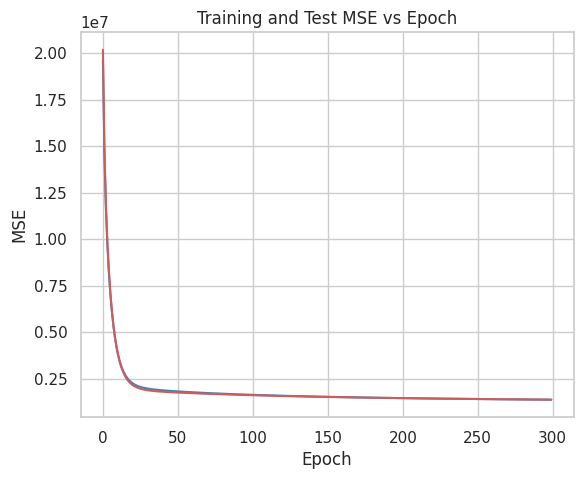

In [250]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(train_mses, label='Training MSE', color='steelblue', linewidth=1.5)
plt.plot(test_mses, label='Test MSE', color='indianred', linewidth=1.5)
plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.title('Training and Test MSE vs Epoch')

# Task 04

In [251]:
def mse_loss_l2(X, y, w, lambda_reg):
    n = X.shape[0]
    predictions = predict(X, w)

    mse = 0.0
    for i in range(n):
        error = predictions[i] - y[i]
        mse += error * error
    mse = mse / n

    penalty = 0.0
    for j in range(1, len(w)):
        penalty += w[j] ** 2
    penalty = (lambda_reg / n) * penalty

    return mse + penalty

In [252]:
def mse_loss_l1(X, y, w, lambda_reg):
    n = X.shape[0]
    predictions = predict(X, w)
    mse = 0.0

    for i in range(n):
        error = predictions[i] - y[i]
        mse += error * error
    mse = mse / n

    penalty = 0.0
    for j in range(1, len(w)):
        penalty += abs(w[j])

    penalty = (lambda_reg / n) * penalty

    return mse + penalty

In [253]:
lambda_test = 100
loss_l2 = mse_loss_l2(X_train_b, y_train, w_final, lambda_test)
loss_l1 = mse_loss_l1(X_train_b, y_train, w_final, lambda_test)

print(f"L2 Ridge loss: {loss_l2:.2f}")
print(f"L1 Lasso loss: {loss_l1:.2f}")

L2 Ridge loss: 1728556.81
L1 Lasso loss: 1359497.62


In [254]:
def compute_gradients_l2(X, y, w, lambda_reg):
    n = X.shape[0]
    d = len(w)
    predictions = predict(X, w)
    gradients = np.zeros(d)

    for j in range(d):
        grad_sum = 0.0
        for i in range(n):
            error = predictions[i] - y[i]
            grad_sum += error * X[i][j]
        gradients[j] = (2 / n) * grad_sum

        if j > 0:
            gradients[j] += (2 * lambda_reg / n) * w[j]

    return gradients

In [255]:
def sign(x):
    if x > 0:
        return 1
    elif x < 0:
        return -1
    else:
        return 0

def compute_gradients_l1(X, y, w, lambda_reg):
    n = X.shape[0]
    d = len(w)
    predictions = predict(X, w)
    gradients = np.zeros(d)

    for j in range(d):
        grad_sum = 0.0
        for i in range(n):
            error = predictions[i] - y[i]
            grad_sum += error * X[i][j]
        gradients[j] = (2 / n) * grad_sum
        if j > 0:
            gradients[j] += (lambda_reg / n) * sign(w[j])

    return gradients

In [256]:
lambda_test = 10
w_small = w_final.copy()
grads_l2 = compute_gradients_l2(X_train_b, y_train, w_small, lambda_test)
grads_l1 = compute_gradients_l1(X_train_b, y_train, w_small, lambda_test)

for i, name in enumerate(feature_names[:5]):
    print(f"{name:8s}: L2 grad = {grads_l2[i]:8.2f}, L1 grad = {grads_l1[i]:8.2f}")

bias    : L2 grad =    -0.00, L1 grad =    -0.00
carat   : L2 grad =   -75.81, L1 grad =   -94.25
cut     : L2 grad =     1.18, L1 grad =     0.57
color   : L2 grad =     0.64, L1 grad =    -1.77
clarity : L2 grad =     6.26, L1 grad =     2.06


In [257]:
def gradient_descent_step_regularized(w, grads, lr):
    w_new = w.copy()
    for i in range(len(w)):
        w_new[i] = w[i] - lr * grads[i]
    return w_new

def train_regularized(X_train, y_train, X_test, y_test, reg_type='l2', lambda_reg=100, learning_rate=0.05, epochs=300, verbose=True):
    n_features = X_train.shape[1]
    w = np.zeros(n_features)

    train_mses = []
    test_mses = []

    for epoch in range(epochs):
        if reg_type == 'l2':
            grads = compute_gradients_l2(X_train, y_train, w, lambda_reg)
        elif reg_type == 'l1':
            grads = compute_gradients_l1(X_train, y_train, w, lambda_reg)
        else:
            raise ValueError("reg_type must be 'l2' or 'l1'")

        w = gradient_descent_step_regularized(w, grads, learning_rate)

        train_mse = mse_loss(X_train, y_train, w)
        test_mse = mse_loss(X_test, y_test, w)
        train_mses.append(train_mse)
        test_mses.append(test_mse)

        if verbose and epoch % 50 == 0:
            print(f"Epoch {epoch:3d}: Train MSE = {train_mse:8.2f}, Test MSE = {test_mse:8.2f}")

    return w, train_mses, test_mses


In [258]:
lambda_val = 100
w_ridge, train_mses_ridge, test_mses_ridge = train_regularized(
    X_train_b, y_train, X_test_b, y_test, reg_type='l2', lambda_reg=lambda_val, learning_rate=0.05, epochs=300, verbose=True
)

w_lasso, train_mses_lasso, test_mses_lasso = train_regularized(
    X_train_b, y_train, X_test_b, y_test, reg_type='l1', lambda_reg=lambda_val, learning_rate=0.05, epochs=300, verbose=True
)

final_mse_unreg = mse_loss(X_test_b, y_test, w_final)
final_mse_ridge = mse_loss(X_test_b, y_test, w_ridge)
final_mse_lasso = mse_loss(X_test_b, y_test, w_lasso)

print(f"Unregularized:     {final_mse_unreg:8.2f}")
print(f"Ridge (L2):        {final_mse_ridge:8.2f}")
print(f"Lasso (L1):        {final_mse_lasso:8.2f}")

if final_mse_ridge < final_mse_unreg:
    print(f"\nRidge improved test MSE by {final_mse_unreg - final_mse_ridge:.2f}")
else:
    print(f"\nRidge did NOT improve test MSE (worse by {final_mse_ridge - final_mse_unreg:.2f})")

if final_mse_lasso < final_mse_unreg:
    print(f"Lasso improved test MSE by {final_mse_unreg - final_mse_lasso:.2f}")
else:
    print(f"Lasso did NOT improve test MSE (worse by {final_mse_lasso - final_mse_unreg:.2f})")

Epoch   0: Train MSE = 19606817.38, Test MSE = 20183216.46
Epoch  50: Train MSE = 1829221.65, Test MSE = 1763597.03
Epoch 100: Train MSE = 1666464.46, Test MSE = 1636920.98
Epoch 150: Train MSE = 1579344.88, Test MSE = 1562459.23
Epoch 200: Train MSE = 1525580.19, Test MSE = 1514611.78
Epoch 250: Train MSE = 1489598.52, Test MSE = 1482353.73
Epoch   0: Train MSE = 19606817.38, Test MSE = 20183216.46
Epoch  50: Train MSE = 1807824.40, Test MSE = 1745065.99
Epoch 100: Train MSE = 1623654.51, Test MSE = 1600465.57
Epoch 150: Train MSE = 1517359.68, Test MSE = 1506947.59
Epoch 200: Train MSE = 1447274.48, Test MSE = 1443052.10
Epoch 250: Train MSE = 1396845.22, Test MSE = 1398075.68
Unregularized:     1366327.39
Ridge (L2):        1460175.43
Lasso (L1):        1366330.26

Ridge did NOT improve test MSE (worse by 93848.04)
Lasso did NOT improve test MSE (worse by 2.87)


# Task 05

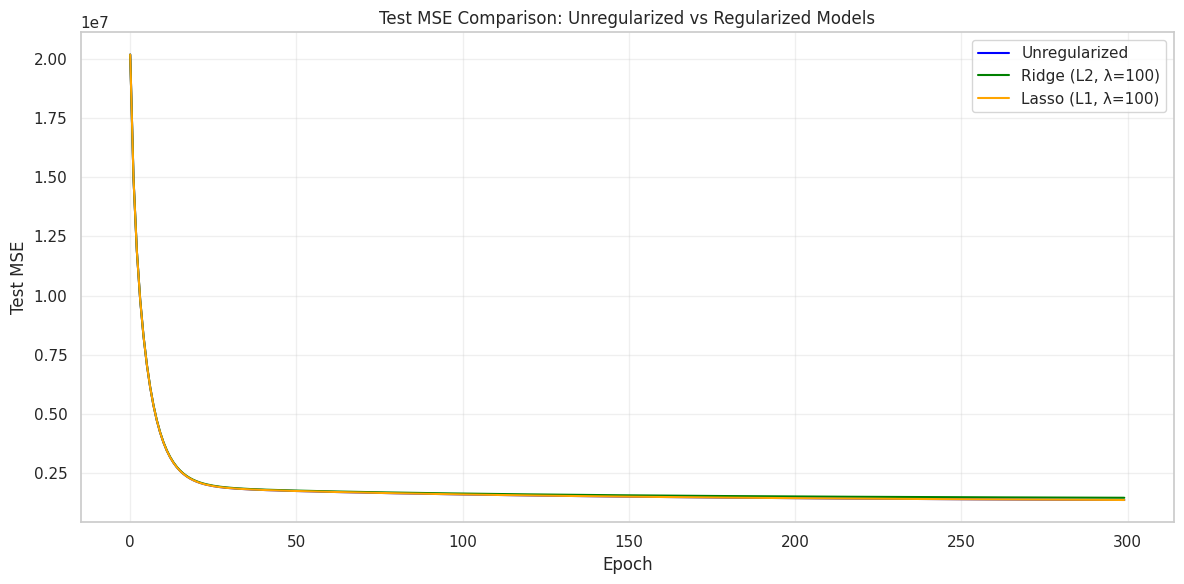

In [259]:
plt.figure(figsize=(12, 6))

plt.plot(test_mses, label='Unregularized', color='blue', linewidth=1.5)
plt.plot(test_mses_ridge, label=f'Ridge (L2, λ={lambda_val})', color='green', linewidth=1.5)
plt.plot(test_mses_lasso, label=f'Lasso (L1, λ={lambda_val})', color='orange', linewidth=1.5)

plt.xlabel('Epoch')
plt.ylabel('Test MSE')
plt.title('Test MSE Comparison: Unregularized vs Regularized Models')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

       1      1749100.73      1813209.16
      10      1750635.10      1814998.47
     100      1767235.16      1834047.85
     500      1862361.60      1937878.90
    1000      2010429.70      2092313.39
    5000      3325590.91      3385214.29

Best λ: 1 with Test MSE = 1749100.73


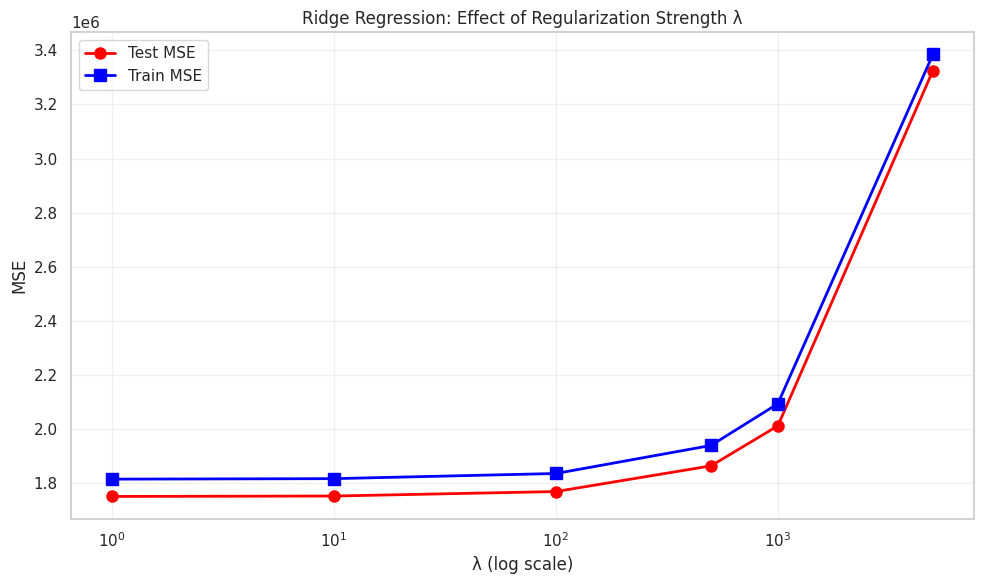

In [260]:
lambda_values = [1, 10, 100, 500, 1000, 5000]
final_test_mses = []
final_train_mses = []

for lam in lambda_values:
    w_ridge_temp, train_mses_temp, test_mses_temp = train_regularized(
        X_train_b, y_train, X_test_b, y_test, reg_type='l2', lambda_reg=lam, learning_rate=0.05, epochs=50, verbose=False
    )
    final_test_mse = test_mses_temp[-1]
    final_train_mse = train_mses_temp[-1]
    final_test_mses.append(final_test_mse)
    final_train_mses.append(final_train_mse)
    print(f"{lam:8d} {final_test_mse:15.2f} {final_train_mse:15.2f}")

best_idx = np.argmin(final_test_mses)
best_lambda = lambda_values[best_idx]
best_mse = final_test_mses[best_idx]

print(f"\nBest λ: {best_lambda} with Test MSE = {best_mse:.2f}")

plt.figure(figsize=(10, 6))
plt.plot(lambda_values, final_test_mses, 'o-', label='Test MSE', color='red', linewidth=2, markersize=8)
plt.plot(lambda_values, final_train_mses, 's-', label='Train MSE', color='blue', linewidth=2, markersize=8)
plt.xscale('log')
plt.xlabel('λ (log scale)')
plt.ylabel('MSE')
plt.title('Ridge Regression: Effect of Regularization Strength λ')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Task 06

In [ ]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error

lambda_val = 100

lr_sklearn = LinearRegression()
lr_sklearn.fit(X_train_scaled, y_train)
y_pred_lr_sklearn = lr_sklearn.predict(X_test_scaled)
mse_lr_sklearn = mean_squared_error(y_test, y_pred_lr_sklearn)

ridge_sklearn = Ridge(alpha=lambda_val)
ridge_sklearn.fit(X_train_scaled, y_train)
y_pred_ridge_sklearn = ridge_sklearn.predict(X_test_scaled)
mse_ridge_sklearn = mean_squared_error(y_test, y_pred_ridge_sklearn)

lasso_sklearn = Lasso(alpha=lambda_val, max_iter=5000)
lasso_sklearn.fit(X_train_scaled, y_train)
y_pred_lasso_sklearn = lasso_sklearn.predict(X_test_scaled)
mse_lasso_sklearn = mean_squared_error(y_test, y_pred_lasso_sklearn)

mse_lr_ours = mse_loss(X_test_b, y_test, w_final)
mse_ridge_ours = mse_loss(X_test_b, y_test, w_ridge)
mse_lasso_ours = mse_loss(X_test_b, y_test, w_lasso)


print("Test MSE Comparison (λ=100):")
print(f"{'Model':<15s} {'My Implementation':>20s} {'Scikit-learn':>15s} {'Difference':>12s}")
print(f"{'Linear':<15s} {mse_lr_ours:20.2f} {mse_lr_sklearn:15.2f} {abs(mse_lr_ours - mse_lr_sklearn):12.2f}")
print(f"{'Ridge (L2)':<15s} {mse_ridge_ours:20.2f} {mse_ridge_sklearn:15.2f} {abs(mse_ridge_ours - mse_ridge_sklearn):12.2f}")
print(f"{'Lasso (L1)':<15s} {mse_lasso_ours:20.2f} {mse_lasso_sklearn:15.2f} {abs(mse_lasso_ours - mse_lasso_sklearn):12.2f}")

In [261]:
sklearn_weights = np.concatenate([[lr_sklearn.intercept_], lr_sklearn.coef_])

print("\nWeight comparison - My Linear Regression vs sklearn LinearRegression:")
print(f"{'Feature':12s} {'My Weights':>15s} {'sklearn Weights':>15s} {'Difference':>12s}")

for i, name in enumerate(feature_names):
    diff = abs(w_final[i] - sklearn_weights[i])
    print(f"{name:<12s} {w_final[i]:15.4f} {sklearn_weights[i]:15.4f} {diff:12.4f}")


Weight comparison - My Linear Regression vs sklearn LinearRegression:
Feature           My Weights sklearn Weights   Difference
bias               3858.1385       3858.1385       0.0000
carat              3687.9621       5613.5958    1925.6337
cut                 123.4980        113.5883       9.9098
color               482.9985        513.4063      30.4078
clarity             839.8868        791.5396      48.3472
depth               -99.4624        -31.1520      68.3104
table               -72.3558        -88.2048      15.8490
x                   325.9349       -491.3541     817.2890
y                  -188.4293        197.8833     386.3126
z                   237.7914      -1236.3243    1474.1157
